# Tutorial 7: Sequence-to-sequence (Seq2Seq) models
Course: **Applied Deep Learning (ECE1553) - FALL 2026**
Instructor: **Dr. Ali Breyhi**
Tutorial: **Saleh Tabatabaei**

**Core task:** Learn to generate a natural-language caption from an image using a CNN encoder and an LSTM decoder.
In this tutorial, you will build an end-to-end image captioning system on **Flickr8k**. The model will use a pretrained **ResNet-50** to encode an image and an **LSTM** to generate a caption one word at a time.

## Learning goals

By the end of the tutorial, you should be able to:

1. Explain image captioning as a conditional Seq2Seq problem.
2. Construct a caption vocabulary from training data only.
3. Prepare variable-length caption sequences for teacher forcing.
4. Use a pretrained ResNet-50 as a visual encoder.
5. Explain what information is retained when the CNN is reduced to an image feature vector.
6. Implement an LSTM decoder for conditional language generation.
7. Explain the LSTM update equations and the role of the image representation.
8. Train the encoder–decoder model with masked cross-entropy.
9. Generate captions autoregressively at test time.
10. Evaluate captions using BLEU and qualitative inspection.
11. Diagnose exposure bias and the difference between training-time and test-time decoding.
12. Run at least one controlled experiment involving encoder fine-tuning, decoder capacity, or decoding strategy.

## References

- Hodosh, Young, and Hockenmaier, **Framing Image Description as a Ranking Task: Data, Models and Evaluation Metrics**  
  https://www.jair.org/index.php/jair/article/view/10833
- Vinyals et al., **Show and Tell: A Neural Image Caption Generator**  
  https://openaccess.thecvf.com/content_cvpr_2015/html/Vinyals_Show_and_Tell_2015_CVPR_paper.html
- He et al., **Deep Residual Learning for Image Recognition**  
  https://arxiv.org/abs/1512.03385
- PyTorch / TorchVision, **Pre-trained Models and ResNet-50**  
  https://docs.pytorch.org/vision/stable/models.html
- Xu et al., **Show, Attend and Tell: Neural Image Caption Generation with Visual Attention**  
  https://arxiv.org/abs/1502.03044

# 1. Image Captioning as a Seq2Seq Problem

The task is to generate a caption from an image.

A useful abstraction is:

```text
image
  ↓
visual encoder
  ↓
image representation
  ↓
language decoder
  ↓
word 1 → word 2 → word 3 → ... → <EOS>
```

Unlike ordinary classification, the output is a **variable-length sequence**. The model must decide both **which word to generate** and **when to stop**.

We model the conditional probability of a caption given an image as:

$$
P(y_{1:T}\mid I)
=
\prod_{t=1}^{T}
P(y_t\mid y_{<t}, I).
$$

The training objective is to maximize the probability of the reference caption, or equivalently minimize the negative log-likelihood:

$$
\mathcal{L}
=
-\sum_{t=1}^{T}
\log P(y_t\mid y_{<t},I).
$$

This is the central Seq2Seq idea for the tutorial.

## 1.1 Flickr8k

Flickr8k contains **8,000 images**, with **five human-written captions per image**. A standard split uses 6,000 images for training, 1,000 for development, and 1,000 for testing.

The multiple captions are important: the same image can be described in several valid ways. Therefore, a generated caption does not need to exactly match one reference sentence to be meaningful.

For this tutorial, keep the split at the **image level**. Do not randomly split individual image-caption pairs, because that would place captions from the same image in both training and test sets.

**Data options**

1. Use the standard Flickr8k directory and caption files.
2. Use a prepared Flickr8k version that already contains train/dev/test assignments.

Expected standard layout:

```text
flickr8k/
├── Flickr8k_Dataset/
│   ├── 1000268201_693b08cb0e.jpg
│   └── ...
└── Flickr8k_text/
    ├── Flickr8k.token.txt
    ├── Flickr_8k.trainImages.txt
    ├── Flickr_8k.devImages.txt
    └── Flickr_8k.testImages.txt
```

In [1]:
import os
import re
import math
import time
import random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

torch.manual_seed(7)
np.random.seed(7)
random.seed(7)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.0.1+cpu
Device: cpu


## 1.2 Configure the dataset

Set `DATA_ROOT` to the location of your Flickr8k files.

If the dataset is not available on your machine, do not silently replace it with another dataset. The task in this tutorial is specifically Flickr8k.

In [3]:
# Change this path to your local Flickr8k directory.
DATA_ROOT = Path("./flickr8k")

IMAGE_DIR = DATA_ROOT / "Flickr8k_Dataset"
TEXT_DIR = DATA_ROOT / "Flickr8k_text"

CAPTION_FILE = TEXT_DIR / "Flickr8k.token.txt"
TRAIN_FILE = TEXT_DIR / "Flickr_8k.trainImages.txt"
DEV_FILE = TEXT_DIR / "Flickr_8k.devImages.txt"
TEST_FILE = TEXT_DIR / "Flickr_8k.testImages.txt"

print("Image directory:", IMAGE_DIR)
print("Caption file:", CAPTION_FILE)
print("Train split:", TRAIN_FILE)
print("Dev split:", DEV_FILE)
print("Test split:", TEST_FILE)

Image directory: flickr8k\Flickr8k_Dataset
Caption file: flickr8k\Flickr8k_text\Flickr8k.token.txt
Train split: flickr8k\Flickr8k_text\Flickr_8k.trainImages.txt
Dev split: flickr8k\Flickr8k_text\Flickr_8k.devImages.txt
Test split: flickr8k\Flickr8k_text\Flickr_8k.testImages.txt


## 1.2.1 Download Flickr8k (run once)

If you do not already have Flickr8k locally, run the next cell. It downloads the **original Flickr8k release** (the same 8,091 images, caption file and official train/dev/test split files) into `DATA_ROOT` and arranges it in the layout shown in Section 1.1.

- Download size: about **1.1 GB** of images plus a 2 MB caption archive.
- The cell is safe to re-run: if the files already exist, it skips them.
- If you already have the dataset somewhere else, just set `DATA_ROOT` above and skip this cell.


In [4]:
# Download Flickr8k (~1.1 GB images + ~2 MB captions) into DATA_ROOT.
# Safe to re-run: anything already present is skipped.
import shutil
import urllib.request
import zipfile

FLICKR8K_URLS = {
    "Flickr8k_Dataset.zip": "https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip",
    "Flickr8k_text.zip": "https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_text.zip",
}
DELETE_ZIPS_AFTER_EXTRACT = True  # set to False to keep the archives


def download_file(url, dest):
    if dest.exists():
        print(f"Already downloaded: {dest.name}")
        return

    tmp = dest.with_name(dest.name + ".part")
    last_pct = [-1]

    def progress(blocks, block_size, total):
        if total <= 0:
            return
        pct = min(100, blocks * block_size * 100 // total)
        if pct != last_pct[0]:
            last_pct[0] = pct
            print(f"\r  {dest.name}: {pct:3d}% of {total / 1e6:.0f} MB", end="", flush=True)

    print(f"Downloading {dest.name} ...")
    urllib.request.urlretrieve(url, tmp, reporthook=progress)
    print()
    tmp.rename(dest)  # only rename once the download finished


def extract_zip(zip_path, out_dir):
    # Extract into a temporary folder first so a half-finished extraction
    # is never mistaken for a complete dataset.
    tmp_dir = out_dir.with_name(out_dir.name + "_tmp")
    shutil.rmtree(tmp_dir, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as zf:
        members = [m for m in zf.namelist() if not m.startswith("__MACOSX")]
        zf.extractall(tmp_dir, members)

    # The image archive wraps everything in a misspelled "Flicker8k_Dataset/" folder;
    # the caption archive has its files at the top level. Handle both.
    entries = list(tmp_dir.iterdir())
    src = entries[0] if len(entries) == 1 and entries[0].is_dir() else tmp_dir
    shutil.move(str(src), str(out_dir))
    shutil.rmtree(tmp_dir, ignore_errors=True)


def download_flickr8k():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    targets = [
        ("Flickr8k_text.zip", TEXT_DIR, CAPTION_FILE),
        ("Flickr8k_Dataset.zip", IMAGE_DIR, IMAGE_DIR),
    ]

    for zip_name, out_dir, done_marker in targets:
        if done_marker.exists():
            print(f"Found {out_dir}, skipping.")
            continue

        zip_path = DATA_ROOT / zip_name
        download_file(FLICKR8K_URLS[zip_name], zip_path)

        print(f"Extracting {zip_name} ...")
        extract_zip(zip_path, out_dir)

        if DELETE_ZIPS_AFTER_EXTRACT:
            zip_path.unlink()

    n_images = len(list(IMAGE_DIR.glob("*.jpg")))
    print(f"Flickr8k ready: {n_images} images in {IMAGE_DIR}")


download_flickr8k()

Found flickr8k\Flickr8k_text, skipping.
Found flickr8k\Flickr8k_Dataset, skipping.
Flickr8k ready: 8091 images in flickr8k\Flickr8k_Dataset


## 1.3 Parse captions and verify the split

Each image has several captions. We will represent the data as:

```text
image_id → [caption_1, caption_2, ..., caption_5]
```

Before building the model, verify three things:

- captions can be parsed,
- the expected image files exist,
- train/dev/test image sets do not overlap.

The last check is not optional. Data leakage at the image level would make the test result misleading.

In [5]:
def read_split_file(path):
    with open(path, "r", encoding="utf-8") as f:
        return {line.strip() for line in f if line.strip()}

def parse_flickr8k_captions(path):
    captions = defaultdict(list)

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            image_tag, caption = line.split("\t", 1)
            image_name = image_tag.split("#")[0]
            captions[image_name].append(caption)

    return dict(captions)

# These checks give a clear error if the dataset has not been mounted.
required = [IMAGE_DIR, CAPTION_FILE, TRAIN_FILE, DEV_FILE, TEST_FILE]
missing = [str(p) for p in required if not p.exists()]

if missing:
    print("Missing Flickr8k paths:")
    for p in missing:
        print("  ", p)
    print("\nSet DATA_ROOT to your local Flickr8k directory before continuing.")
else:
    captions = parse_flickr8k_captions(CAPTION_FILE)
    train_images = read_split_file(TRAIN_FILE)
    dev_images = read_split_file(DEV_FILE)
    test_images = read_split_file(TEST_FILE)

    print("Images with captions:", len(captions))
    print("Train images:", len(train_images))
    print("Dev images:", len(dev_images))
    print("Test images:", len(test_images))

    assert train_images.isdisjoint(dev_images)
    assert train_images.isdisjoint(test_images)
    assert dev_images.isdisjoint(test_images)

    print("Image-level split check: PASSED")

Images with captions: 8092
Train images: 6000
Dev images: 1000
Test images: 1000
Image-level split check: PASSED


# 2. Caption Processing

The decoder does not operate directly on strings. We first convert each caption into a sequence of tokens.

For example:

```text
"A dog is running through grass."
```

becomes approximately:

```text
<BOS> a dog is running through grass <EOS>
```

The special tokens have specific roles:

- `<PAD>`: fills unused positions in a batch
- `<BOS>`: tells the decoder to start generating
- `<EOS>`: tells the decoder to stop
- `<UNK>`: represents a word outside the vocabulary

Build the vocabulary using **training captions only**. This avoids allowing information from the dev/test captions to influence the model vocabulary.

In [6]:
SPECIAL_TOKENS = ["<PAD>", "<BOS>", "<EOS>", "<UNK>"]

def tokenize(text):
    text = text.lower().strip()
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", text)

def build_vocab(captions_by_image, image_names, min_freq=2):
    counter = Counter()

    for image_name in image_names:
        for caption in captions_by_image[image_name]:
            counter.update(tokenize(caption))

    itos = SPECIAL_TOKENS.copy()
    for token, freq in counter.most_common():
        if freq >= min_freq and token not in itos:
            itos.append(token)

    stoi = {token: idx for idx, token in enumerate(itos)}
    return stoi, itos, counter

if "captions" in globals():
    stoi, itos, word_counts = build_vocab(captions, train_images, min_freq=2)

    PAD_ID = stoi["<PAD>"]
    BOS_ID = stoi["<BOS>"]
    EOS_ID = stoi["<EOS>"]
    UNK_ID = stoi["<UNK>"]

    print("Vocabulary size:", len(itos))
    print("Most common words:", word_counts.most_common(15))

Vocabulary size: 4448
Most common words: [('a', 46784), ('in', 14094), ('the', 13509), ('on', 8007), ('is', 6907), ('and', 6678), ('dog', 6160), ('with', 5763), ('man', 5383), ('of', 4974), ('two', 4250), ('white', 2932), ('black', 2865), ('boy', 2634), ('are', 2619)]


## 2.1 Numericalize captions

For a caption with target tokens

$$
[y_1,y_2,\ldots,y_T],
$$

teacher forcing uses two shifted sequences:

$$
\text{decoder input}
=
[\text{BOS},y_1,y_2,\ldots,y_{T-1}]
$$

and

$$
\text{target}
=
[y_1,y_2,\ldots,y_{T-1},\text{EOS}].
$$

At each time step, the decoder receives the correct previous word during training. Later, during testing, this information is unavailable and the model must feed its own prediction back into the next step.

In [7]:
def encode_caption(caption, stoi):
    tokens = ["<BOS>"] + tokenize(caption) + ["<EOS>"]
    return [stoi.get(tok, UNK_ID) for tok in tokens]

if "captions" in globals():
    example_image = sorted(train_images)[0]
    example_caption = captions[example_image][0]
    encoded = encode_caption(example_caption, stoi)

    print("Caption:")
    print(example_caption)
    print("\nTokens:")
    print(["<BOS>"] + tokenize(example_caption) + ["<EOS>"])
    print("\nIDs:")
    print(encoded)

Caption:
A child in a pink dress is climbing up a set of stairs in an entry way .

Tokens:
['<BOS>', 'a', 'child', 'in', 'a', 'pink', 'dress', 'is', 'climbing', 'up', 'a', 'set', 'of', 'stairs', 'in', 'an', 'entry', 'way', '<EOS>']

IDs:
[1, 4, 44, 5, 4, 89, 174, 8, 118, 54, 4, 394, 13, 399, 5, 29, 3, 636, 2]


# 3. Visual Encoder: ResNet-50

The encoder converts the image into a compact representation that the language decoder can use.

We start from a pretrained ResNet-50:

```text
image
  ↓
ResNet-50 convolutional layers
  ↓
global average pooling
  ↓
2048-dimensional visual feature
  ↓
projection to decoder dimension
```

The classification layer is removed because the decoder does not need an ImageNet class prediction. We want the representation produced by the visual backbone.

Conceptually, the encoder computes:

$$
v=f_{\theta}(I).
$$

For the ResNet-50 backbone used here, the pooled feature has dimension:

$$
v\in\mathbb{R}^{2048}.
$$

We then map it to the LSTM hidden dimension:

$$
z=W_vv+b_v.
$$

This tutorial initially **freezes ResNet-50** so that most of the optimization is focused on learning the image-to-language interface. Fine-tuning the encoder is an optional experiment later.

In [8]:
weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights)

# Remove the ImageNet classification head.
encoder_backbone = nn.Sequential(*list(resnet.children())[:-1])

encoder_preprocess = weights.transforms()

print("ResNet-50 loaded.")
print("Expected pooled feature dimension: 2048")

ResNet-50 loaded.
Expected pooled feature dimension: 2048


## 3.1 Implement the encoder

The encoder exposes two useful modes:

- **frozen**: only the projection into the decoder is trained;
- **fine-tuned**: selected ResNet parameters can also be updated.

Starting with a frozen backbone gives you a controlled baseline. Do not assume that fine-tuning is automatically better: Flickr8k is small, and a large visual backbone can overfit.

In [9]:
class ImageEncoder(nn.Module):
    def __init__(self, hidden_dim, fine_tune=False):
        super().__init__()

        weights = ResNet50_Weights.DEFAULT
        backbone = resnet50(weights=weights)

        self.cnn = nn.Sequential(*list(backbone.children())[:-1])
        self.feature_dim = 2048
        self.projection = nn.Linear(self.feature_dim, hidden_dim)

        self.set_fine_tune(fine_tune)

    def set_fine_tune(self, fine_tune):
        for p in self.cnn.parameters():
            p.requires_grad = fine_tune

    def forward(self, images):
        features = self.cnn(images)
        features = features.flatten(1)
        return self.projection(features)

encoder = ImageEncoder(hidden_dim=256, fine_tune=False).to(device)

trainable = sum(p.numel() for p in encoder.parameters() if p.requires_grad)
total = sum(p.numel() for p in encoder.parameters())

print(f"Total encoder parameters: {total:,}")
print(f"Trainable encoder parameters: {trainable:,}")

Total encoder parameters: 24,032,576
Trainable encoder parameters: 524,544


## 3.2 Inspect an image and its captions

Before training a multimodal model, inspect the actual data.

Look at several images and all five reference captions. Notice that the captions may describe the same image using different wording.

This is an important property of image captioning: there can be multiple reasonable outputs for the same visual input.

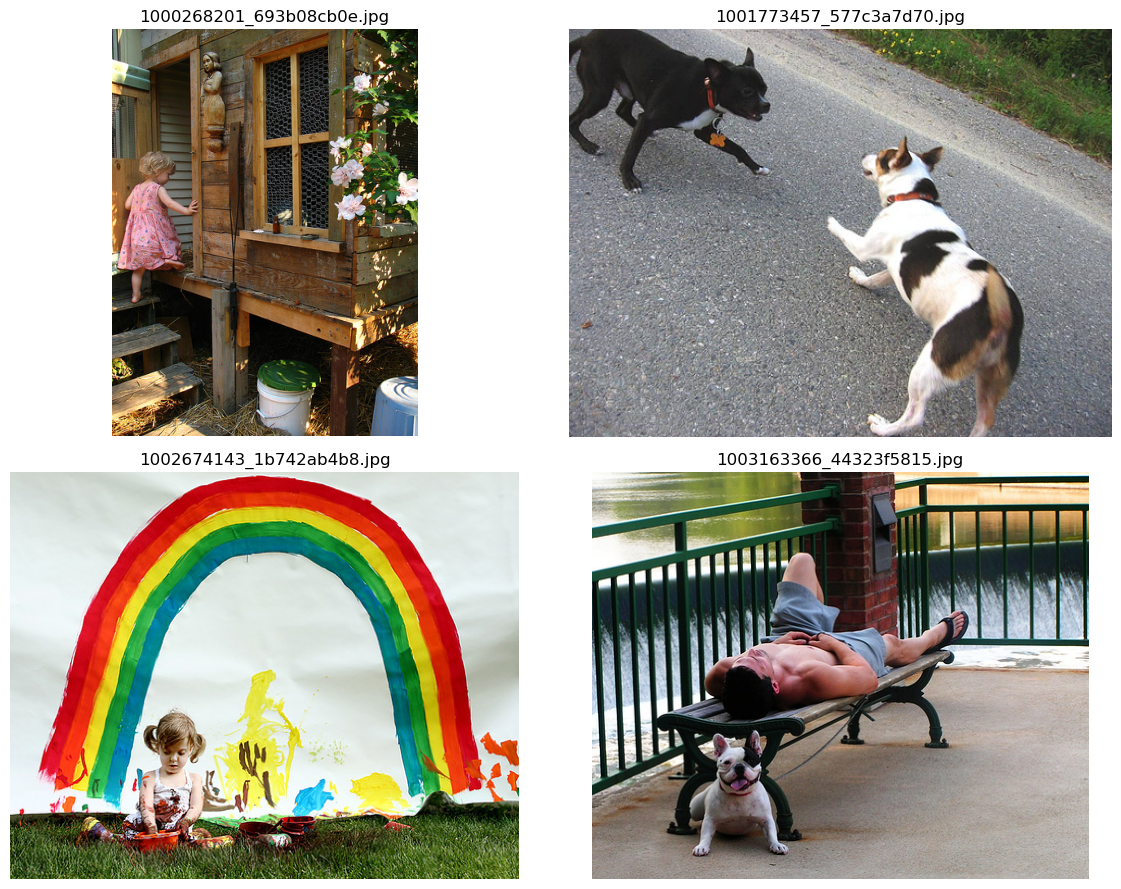


 1000268201_693b08cb0e.jpg
 - A child in a pink dress is climbing up a set of stairs in an entry way .
 - A girl going into a wooden building .
 - A little girl climbing into a wooden playhouse .
 - A little girl climbing the stairs to her playhouse .
 - A little girl in a pink dress going into a wooden cabin .

 1001773457_577c3a7d70.jpg
 - A black dog and a spotted dog are fighting
 - A black dog and a tri-colored dog playing with each other on the road .
 - A black dog and a white dog with brown spots are staring at each other in the street .
 - Two dogs of different breeds looking at each other on the road .
 - Two dogs on pavement moving toward each other .

 1002674143_1b742ab4b8.jpg
 - A little girl covered in paint sits in front of a painted rainbow with her hands in a bowl .
 - A little girl is sitting in front of a large painted rainbow .
 - A small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it .
 - There is a girl with pigtails si

In [10]:
if "captions" in globals():
    sample_names = sorted(train_images)[:4]

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.ravel()

    for ax, image_name in zip(axes, sample_names):
        image = Image.open(IMAGE_DIR / image_name).convert("RGB")
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(image_name)

    plt.tight_layout()
    plt.show()

    for image_name in sample_names[:4]:
        print("\n", image_name)
        for c in captions[image_name]:
            print(" -", c)

# 4. LSTM Decoder

The decoder is a conditional language model.

At each time step, it receives:

1. the previous word embedding,
2. its recurrent hidden state,
3. information derived from the image.

The LSTM maintains a cell state and a hidden state. For input embedding $$
x_t
$$ and previous hidden state $$
h_{t-1}
$$ and cell state $$
c_{t-1}
$$:

$$
i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i)
$$

$$
f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f)
$$

$$
o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o)
$$

$$
g_t=\tanh(W_g x_t+U_g h_{t-1}+b_g)
$$

$$
c_t=f_t\odot c_{t-1}+i_t\odot g_t
$$

$$
h_t=o_t\odot\tanh(c_t).
$$

The output distribution over the vocabulary is:

$$
p(y_t\mid y_{<t},I)
=
\operatorname{softmax}(W_p h_t+b_p).
$$

The important modeling question is therefore: **how should the image representation initialize or condition the LSTM?**

## 4.1 Conditioning the LSTM on the image

We will use the projected image feature to initialize both the hidden state and cell state:

$$
h_0=W_hz+b_h
$$

$$
c_0=W_cz+b_c.
$$

This creates a clean interface between the CNN and LSTM:

```text
ResNet image feature
        ↓
projection
   ↙         ↘
h₀            c₀
   ↘         ↙
       LSTM
        ↓
     caption
```

This is deliberately simpler than an attention-based captioning model. The image is compressed into one vector before decoding. Later, you can investigate what this bottleneck loses.

In [11]:
class LSTMDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=256,
        hidden_dim=256,
        num_layers=1,
        dropout=0.2,
    ):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)

        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )

        self.image_to_h = nn.Linear(hidden_dim, hidden_dim * num_layers)
        self.image_to_c = nn.Linear(hidden_dim, hidden_dim * num_layers)

        self.output = nn.Linear(hidden_dim, vocab_size)

    def init_state(self, image_features):
        batch_size = image_features.size(0)

        h0 = self.image_to_h(image_features)
        c0 = self.image_to_c(image_features)

        h0 = h0.view(batch_size, self.num_layers, self.hidden_dim)
        c0 = c0.view(batch_size, self.num_layers, self.hidden_dim)

        h0 = h0.transpose(0, 1).contiguous()
        c0 = c0.transpose(0, 1).contiguous()

        return h0, c0

    def forward(self, image_features, captions_in):
        embeddings = self.embedding(captions_in)
        state = self.init_state(image_features)

        outputs, _ = self.lstm(embeddings, state)
        logits = self.output(outputs)

        return logits

decoder = LSTMDecoder(
    vocab_size=len(itos) if "itos" in globals() else 10000,
    embed_dim=256,
    hidden_dim=256,
    num_layers=1,
).to(device)

print(decoder)

LSTMDecoder(
  (embedding): Embedding(4448, 256, padding_idx=0)
  (lstm): LSTM(256, 256, batch_first=True)
  (image_to_h): Linear(in_features=256, out_features=256, bias=True)
  (image_to_c): Linear(in_features=256, out_features=256, bias=True)
  (output): Linear(in_features=256, out_features=4448, bias=True)
)


# 5. Build the Image Captioning Dataset

Each training example pairs one image with one of its reference captions.

Because captions have different lengths, batches require padding.

For a batch, the tensors have the following conceptual shapes:

```text
images
    (B, 3, H, W)

decoder input
    (B, T)

target
    (B, T)

logits
    (B, T, V)
```

where $$
B
$$ is the batch size, $$
T
$$ is the padded caption length, and $$
V
$$ is the vocabulary size.

In [12]:
class FlickrCaptionDataset(Dataset):
    def __init__(self, image_names, captions_by_image, image_dir, stoi, transform):
        self.image_dir = Path(image_dir)
        self.stoi = stoi
        self.transform = transform

        self.samples = []
        for image_name in sorted(image_names):
            for caption in captions_by_image[image_name]:
                self.samples.append((image_name, caption))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_name, caption = self.samples[idx]

        image = Image.open(self.image_dir / image_name).convert("RGB")
        image = self.transform(image)

        ids = encode_caption(caption, self.stoi)
        ids = torch.tensor(ids, dtype=torch.long)

        return image, ids, image_name, caption


train_transform = encoder_preprocess
eval_transform = encoder_preprocess

if "captions" in globals():
    train_dataset = FlickrCaptionDataset(
        train_images, captions, IMAGE_DIR, stoi, train_transform
    )
    dev_dataset = FlickrCaptionDataset(
        dev_images, captions, IMAGE_DIR, stoi, eval_transform
    )

    print("Training image-caption pairs:", len(train_dataset))
    print("Development image-caption pairs:", len(dev_dataset))

Training image-caption pairs: 30000
Development image-caption pairs: 5000


In [13]:
def caption_collate(batch):
    images, captions_list, image_names, raw_captions = zip(*batch)

    images = torch.stack(images)

    lengths = torch.tensor(
        [len(c) for c in captions_list],
        dtype=torch.long,
    )

    max_len = max(lengths).item()

    padded = torch.full(
        (len(captions_list), max_len),
        PAD_ID,
        dtype=torch.long,
    )

    for i, caption in enumerate(captions_list):
        padded[i, :len(caption)] = caption

    # Teacher forcing:
    # input  = BOS, word_1, ..., word_(T-1)
    # target = word_1, ..., word_(T-1), EOS
    captions_in = padded[:, :-1]
    targets = padded[:, 1:]

    return {
        "images": images,
        "captions_in": captions_in,
        "targets": targets,
        "lengths": lengths - 1,
        "image_names": image_names,
        "raw_captions": raw_captions,
    }


if "train_dataset" in globals():
    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
        collate_fn=caption_collate,
        pin_memory=torch.cuda.is_available(),
    )

    dev_loader = DataLoader(
        dev_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0,
        collate_fn=caption_collate,
        pin_memory=torch.cuda.is_available(),
    )

    batch = next(iter(train_loader))

    for key, value in batch.items():
        if torch.is_tensor(value):
            print(key, tuple(value.shape))
        else:
            print(key, type(value))

images (32, 3, 224, 224)
captions_in (32, 19)
targets (32, 19)
lengths (32,)
image_names <class 'tuple'>
raw_captions <class 'tuple'>


# 6. Complete Seq2Seq Image Captioning Model

The complete model is:

```text
                         ┌──────────────────┐
                         │   ResNet-50      │
image ──────────────────►│ visual encoder   │
                         └────────┬─────────┘
                                  │
                                  ▼
                         image representation
                                  │
                          ┌───────┴───────┐
                          ▼               ▼
                         h₀              c₀
                          │               │
                          └──────┬────────┘
                                 ▼
                         ┌───────────────┐
 BOS → word₁ → word₂ →  │     LSTM      │
                         └───────┬───────┘
                                 ▼
                         vocabulary logits
                                 │
                                 ▼
                         next-word prediction
```

The model is trained using reference captions, but at test time it must generate a caption without seeing the reference words.

In [14]:
class ImageCaptioningModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=256,
        hidden_dim=256,
        num_layers=1,
        dropout=0.2,
        fine_tune_encoder=False,
    ):
        super().__init__()

        self.encoder = ImageEncoder(
            hidden_dim=hidden_dim,
            fine_tune=fine_tune_encoder,
        )

        self.decoder = LSTMDecoder(
            vocab_size=vocab_size,
            embed_dim=embed_dim,
            hidden_dim=hidden_dim,
            num_layers=num_layers,
            dropout=dropout,
        )

    def forward(self, images, captions_in):
        image_features = self.encoder(images)
        logits = self.decoder(image_features, captions_in)
        return logits


if "itos" in globals():
    model = ImageCaptioningModel(
        vocab_size=len(itos),
        embed_dim=256,
        hidden_dim=256,
        num_layers=1,
        dropout=0.2,
        fine_tune_encoder=False,
    ).to(device)

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 26,972,320
Trainable parameters: 3,464,288


## 6.1 Shape check

Before training, verify that the model produces the expected tensor dimensions.

For a batch:

$$
\text{images}\in\mathbb{R}^{B\times3\times H\times W}
$$

$$
\text{decoder input}\in\mathbb{N}^{B\times T}
$$

$$
\text{logits}\in\mathbb{R}^{B\times T\times V}.
$$

If these dimensions are wrong, stop here and fix them before training.

In [15]:
if "model" in globals() and "batch" in globals():
    images = batch["images"].to(device)
    captions_in = batch["captions_in"].to(device)
    targets = batch["targets"].to(device)

    with torch.no_grad():
        logits = model(images, captions_in)

    print("images      :", tuple(images.shape))
    print("captions_in :", tuple(captions_in.shape))
    print("targets     :", tuple(targets.shape))
    print("logits      :", tuple(logits.shape))

    assert logits.shape[:2] == targets.shape
    assert logits.shape[-1] == len(itos)

    print("Shape check: PASSED")

images      : (32, 3, 224, 224)
captions_in : (32, 19)
targets     : (32, 19)
logits      : (32, 19, 4448)
Shape check: PASSED


# 7. Training Objective

At each position, the model predicts the next token.

The loss is cross-entropy over all non-padding target tokens:

$$
\mathcal{L}
=
-\frac{1}{N}
\sum_{n=1}^{N}
\log
P(y_n\mid y_{<n},I).
$$

Padding positions do not correspond to real targets, so they must be ignored.

We will use:

- AdamW,
- gradient clipping,
- validation loss,
- checkpointing based on development loss.

Do not judge the model only from training loss. The real question is whether the model generates useful captions for images it has not seen.

In [16]:
def sequence_loss(logits, targets):
    vocab_size = logits.size(-1)

    return F.cross_entropy(
        logits.reshape(-1, vocab_size),
        targets.reshape(-1),
        ignore_index=PAD_ID,
    )


def train_one_epoch(model, loader, optimizer, clip_grad=1.0):
    model.train()

    total_loss = 0.0
    total_tokens = 0

    for batch in loader:
        images = batch["images"].to(device, non_blocking=True)
        captions_in = batch["captions_in"].to(device, non_blocking=True)
        targets = batch["targets"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images, captions_in)
        loss = sequence_loss(logits, targets)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
        optimizer.step()

        non_pad = (targets != PAD_ID).sum().item()
        total_loss += loss.item() * non_pad
        total_tokens += non_pad

    return total_loss / max(total_tokens, 1)


@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for batch in loader:
        images = batch["images"].to(device, non_blocking=True)
        captions_in = batch["captions_in"].to(device, non_blocking=True)
        targets = batch["targets"].to(device, non_blocking=True)

        logits = model(images, captions_in)
        loss = sequence_loss(logits, targets)

        non_pad = (targets != PAD_ID).sum().item()
        total_loss += loss.item() * non_pad
        total_tokens += non_pad

    return total_loss / max(total_tokens, 1)

## 7.1 Train the model

Start with a frozen ResNet encoder.

A reasonable first experiment is to train the decoder and image projection for several epochs, then inspect generated captions. If the model is learning, the development loss should decrease and the generated text should become less random.

The exact training time depends strongly on your hardware. On a GPU, the full Flickr8k experiment is practical; on CPU, begin with a small subset to verify that the pipeline works.

In [17]:
# Training configuration
EPOCHS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

if "model" in globals() and "train_loader" in globals():
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    best_dev = float("inf")
    history = {"train": [], "dev": []}

    for epoch in range(1, EPOCHS + 1):
        start = time.time()

        train_loss = train_one_epoch(model, train_loader, optimizer)
        dev_loss = evaluate_loss(model, dev_loader)

        history["train"].append(train_loss)
        history["dev"].append(dev_loss)

        elapsed = time.time() - start

        print(
            f"Epoch {epoch:02d} | "
            f"train loss: {train_loss:.4f} | "
            f"dev loss: {dev_loss:.4f} | "
            f"time: {elapsed:.1f}s"
        )

        if dev_loss < best_dev:
            best_dev = dev_loss
            torch.save(model.state_dict(), "week9_best_caption_model.pt")

    print("Best development loss:", best_dev)

Epoch 01 | train loss: 4.3886 | dev loss: 3.7751 | time: 3593.3s
Epoch 02 | train loss: 3.5594 | dev loss: 3.4120 | time: 2023.7s
Epoch 03 | train loss: 3.2291 | dev loss: 3.2183 | time: 1547.8s
Epoch 04 | train loss: 3.0127 | dev loss: 3.1074 | time: 1550.5s
Epoch 05 | train loss: 2.8528 | dev loss: 3.0329 | time: 1554.1s
Epoch 06 | train loss: 2.7244 | dev loss: 2.9852 | time: 1558.9s
Epoch 07 | train loss: 2.6160 | dev loss: 2.9561 | time: 1553.7s
Epoch 08 | train loss: 2.5218 | dev loss: 2.9285 | time: 1555.2s
Best development loss: 2.9285337187585174


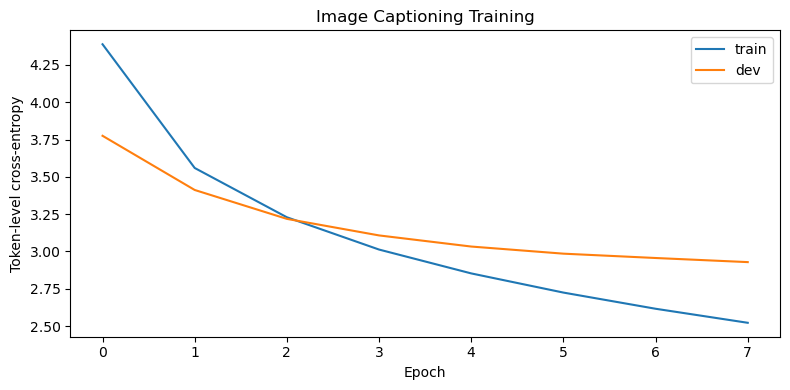

In [18]:
if "history" in globals():
    plt.figure(figsize=(8, 4))
    plt.plot(history["train"], label="train")
    plt.plot(history["dev"], label="dev")
    plt.xlabel("Epoch")
    plt.ylabel("Token-level cross-entropy")
    plt.title("Image Captioning Training")
    plt.legend()
    plt.tight_layout()
    plt.show()

# 8. Autoregressive Caption Generation

During training, the decoder receives the correct previous token.

At test time, it does not.

Generation therefore follows:

```text
<BOS>
  ↓
predict word₁
  ↓
feed word₁ back into the decoder
  ↓
predict word₂
  ↓
feed word₂ back into the decoder
  ↓
...
  ↓
<EOS>
```

The generated sequence is therefore produced according to:

$$
\hat{y}_t
=
\arg\max_{y}
P(y\mid \hat{y}_{<t},I).
$$

This difference between training and inference is one of the most important ideas in Seq2Seq modeling.

In [19]:
@torch.no_grad()
def generate_caption(model, image_tensor, max_len=25):
    model.eval()

    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    image_features = model.encoder(image_tensor)

    generated = [BOS_ID]
    state = model.decoder.init_state(image_features)

    for _ in range(max_len):
        current = torch.tensor(
            [[generated[-1]]],
            dtype=torch.long,
            device=device,
        )

        embedding = model.decoder.embedding(current)

        output, state = model.decoder.lstm(
            embedding,
            state,
        )

        logits = model.decoder.output(output[:, -1])
        next_token = logits.argmax(dim=-1).item()

        generated.append(next_token)

        if next_token == EOS_ID:
            break

    words = []
    for idx in generated[1:]:
        if idx == EOS_ID:
            break
        if idx not in (PAD_ID, BOS_ID):
            words.append(itos[idx])

    return words


def caption_text(words):
    return " ".join(words)

## 8.1 Qualitative evaluation

Automated metrics are useful, but image captioning should also be inspected visually.

For each test image, compare:

- the image,
- the generated caption,
- all human reference captions.

Ask:

1. Did the model identify the main subject?
2. Did it identify the main action?
3. Is the generated sentence grammatical?
4. Does it hallucinate an object that is not present?
5. Is it overly generic?
6. Does it copy common sentence patterns from the training set?

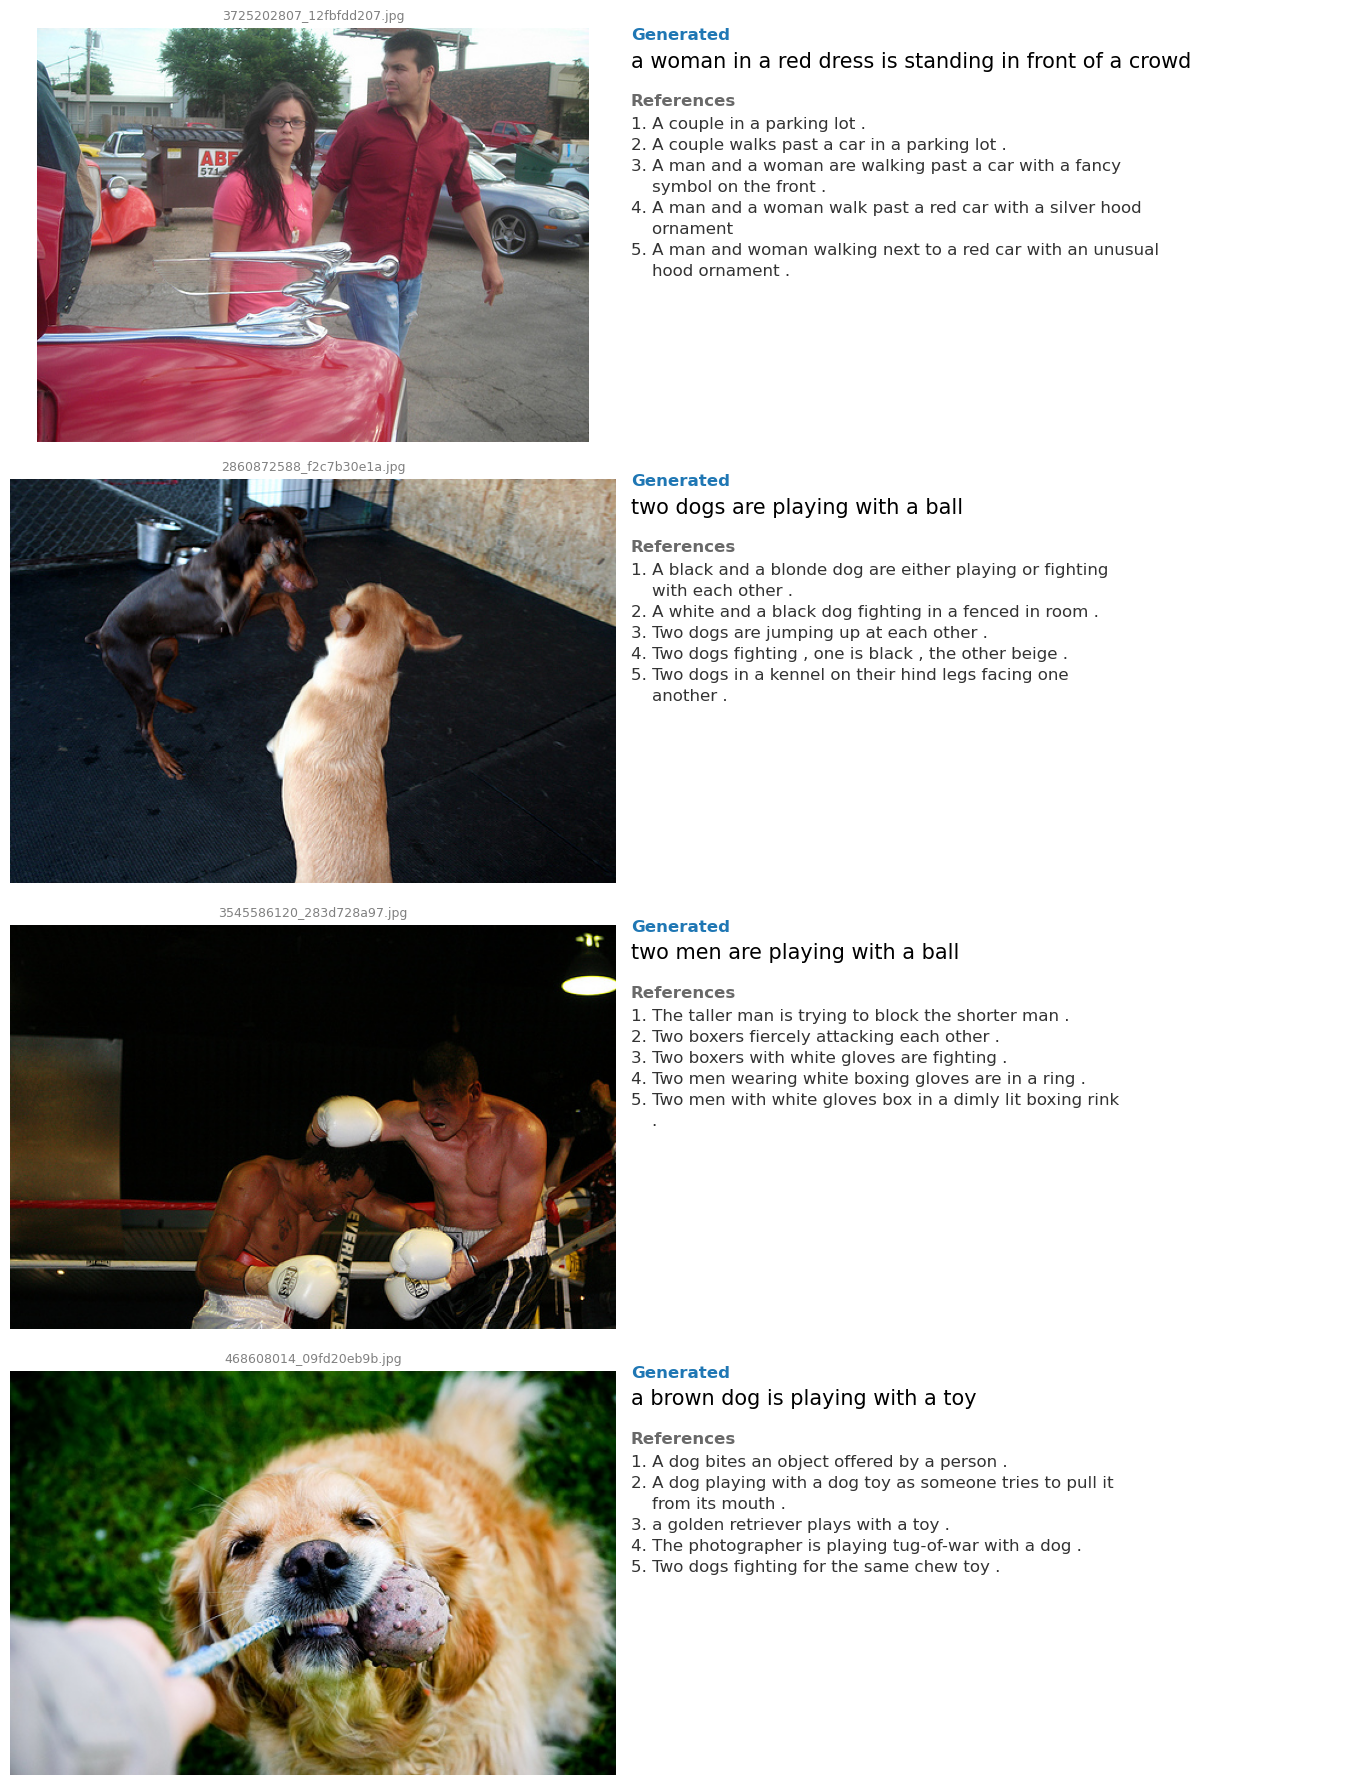

In [29]:
import textwrap


def show_caption_examples(model, image_names, n=4, seed=0, wrap=60):
    # Pick a reproducible random sample so the examples are varied
    # (the first images in sorted order are not representative).
    rng = random.Random(seed)
    chosen = rng.sample(sorted(image_names), min(n, len(image_names)))

    fig, axes = plt.subplots(
        len(chosen), 2,
        figsize=(14, 4.5 * len(chosen)),
        gridspec_kw={"width_ratios": [1, 1.2]},
    )
    axes = np.atleast_2d(axes)

    for (ax_img, ax_txt), image_name in zip(axes, chosen):
        image = Image.open(IMAGE_DIR / image_name).convert("RGB")
        generated = caption_text(generate_caption(model, eval_transform(image)))

        # Left: the image.
        ax_img.imshow(image)
        ax_img.axis("off")
        ax_img.set_title(image_name, fontsize=9, color="gray")

        # Right: generated caption on top, the five human references below.
        ax_txt.axis("off")
        header = ax_txt.text(
            0.0, 1.0, "Generated",
            transform=ax_txt.transAxes, va="top",
            fontsize=12, fontweight="bold", color="tab:blue",
        )
        gen = ax_txt.annotate(
            textwrap.fill(generated, wrap),
            xy=(0, 0), xycoords=header,
            xytext=(0, -6), textcoords="offset points",
            va="top", fontsize=15,
        )
        refs_header = ax_txt.annotate(
            "References",
            xy=(0, 0), xycoords=gen,
            xytext=(0, -16), textcoords="offset points",
            va="top", fontsize=12, fontweight="bold", color="dimgray",
        )
        refs = "\n".join(
            textwrap.fill(f"{i}. {c}", wrap, subsequent_indent="    ")
            for i, c in enumerate(captions[image_name], 1)
        )
        ax_txt.annotate(
            refs,
            xy=(0, 0), xycoords=refs_header,
            xytext=(0, -6), textcoords="offset points",
            va="top", fontsize=12, color="#333333", linespacing=1.5,
        )

    plt.tight_layout()
    plt.show()


if "model" in globals() and "test_images" in globals():
    # Load the best checkpoint before qualitative evaluation.
    checkpoint = Path("week9_best_caption_model.pt")
    if checkpoint.exists():
            model.load_state_dict(torch.load(checkpoint, map_location=device))

    show_caption_examples(model, test_images, n=4)

# 9. Quantitative Evaluation

A common automatic metric for caption generation is BLEU, which measures overlap between generated text and reference text at different n-gram orders.

BLEU-1 focuses on individual words, while BLEU-4 requires longer matching sequences.

For a generated caption $$
c
$$ and reference captions $$
R
$$, the basic BLEU idea is to compare modified n-gram precision across several values of $$
n
$$.

The metric should **not** be interpreted as a complete measure of caption quality. Two valid captions can use different words and receive a low overlap score.

For Flickr8k, use the five reference captions for each test image rather than evaluating against only one reference.

In [21]:
# NLTK is used only for evaluation.
# If it is unavailable, install it in your environment before running this cell.
try:
    from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
    nltk_available = True
except ImportError:
    nltk_available = False
    print("NLTK is not installed. Install nltk to run BLEU evaluation.")


@torch.no_grad()
def evaluate_bleu(model, image_names):
    if not nltk_available:
        return None

    references = []
    hypotheses = []

    smooth = SmoothingFunction().method1

    for image_name in image_names:
        image = Image.open(IMAGE_DIR / image_name).convert("RGB")
        image_tensor = eval_transform(image)

        generated = generate_caption(model, image_tensor)

        refs = [
            tokenize(caption)
            for caption in captions[image_name]
        ]

        references.append(refs)
        hypotheses.append(generated)

    scores = {
        "BLEU-1": corpus_bleu(
            references,
            hypotheses,
            weights=(1, 0, 0, 0),
            smoothing_function=smooth,
        ),
        "BLEU-2": corpus_bleu(
            references,
            hypotheses,
            weights=(0.5, 0.5, 0, 0),
            smoothing_function=smooth,
        ),
        "BLEU-3": corpus_bleu(
            references,
            hypotheses,
            weights=(1/3, 1/3, 1/3, 0),
            smoothing_function=smooth,
        ),
        "BLEU-4": corpus_bleu(
            references,
            hypotheses,
            weights=(0.25, 0.25, 0.25, 0.25),
            smoothing_function=smooth,
        ),
    }

    return scores


if "model" in globals() and "test_images" in globals() and "captions" in globals():
    bleu_scores = evaluate_bleu(model, sorted(test_images))

    if bleu_scores is not None:
        for metric, score in bleu_scores.items():
            print(f"{metric}: {score:.4f}")

BLEU-1: 0.5845
BLEU-2: 0.4044
BLEU-3: 0.2691
BLEU-4: 0.1783


# 10. Train vs Test: Exposure Bias

There is an important mismatch in this model.

During training:

$$
P(y_t\mid y_{<t},I)
$$

is evaluated using the **ground-truth previous words**.

During generation:

$$
P(y_t\mid \hat{y}_{<t},I)
$$

depends on the model's own previous predictions.

A single early mistake can therefore influence every later prediction.

This is called **exposure bias**. It is one reason why a low teacher-forced validation loss does not guarantee strong free-running generation.

### Think about it

If the model predicts one wrong word at time step 3, what happens at time step 4?

The decoder now receives its own incorrect prediction rather than the correct reference word.

That creates a distribution shift between training and inference.

# 11. Controlled Experiment: Frozen vs Fine-Tuned ResNet

Now raise the difficulty.

The baseline freezes the ResNet-50 encoder. Your next experiment is to allow the encoder to update.

The comparison should keep everything else fixed:

```text
Experiment A:
frozen ResNet + LSTM decoder

Experiment B:
fine-tuned ResNet + LSTM decoder
```

Compare:

- development loss,
- BLEU-1 to BLEU-4,
- training time,
- qualitative captions,
- signs of overfitting.

Do not report only which experiment has the higher BLEU score. Explain **why** the result may have occurred.

In [22]:
# OPTIONAL EXPERIMENT SETUP

# Recreate the model with a fine-tunable encoder.
if "itos" in globals():
    finetune_model = ImageCaptioningModel(
        vocab_size=len(itos),
        embed_dim=256,
        hidden_dim=256,
        num_layers=1,
        dropout=0.2,
        fine_tune_encoder=True,
    ).to(device)

    # Use a smaller learning rate for the pretrained CNN.
    encoder_params = []
    decoder_params = []

    for name, param in finetune_model.named_parameters():
        if not param.requires_grad:
            continue
        if name.startswith("encoder.cnn"):
            encoder_params.append(param)
        else:
            decoder_params.append(param)

    optimizer_ft = torch.optim.AdamW(
        [
            {"params": encoder_params, "lr": 1e-5},
            {"params": decoder_params, "lr": 3e-4},
        ],
        weight_decay=1e-4,
    )

    print("Fine-tuning experiment is ready.")
    print("Encoder trainable parameters:",
          f"{sum(p.numel() for p in encoder_params):,}")
    print("Decoder/projector trainable parameters:",
          f"{sum(p.numel() for p in decoder_params):,}")

Fine-tuning experiment is ready.
Encoder trainable parameters: 23,508,032
Decoder/projector trainable parameters: 3,464,288


# 12. Optional Extension: Beam Search

Greedy decoding chooses the most probable word at every step:

$$
\hat{y}_t
=
\arg\max_y
P(y\mid \hat{y}_{<t},I).
$$

This is fast, but it does not necessarily find the highest-probability complete sequence.

Beam search keeps several candidate sequences at the same time.

For a beam width of $$
k
$$, the decoder maintains the best $$
k
$$ partial sequences according to their accumulated log-probability.

Try beam widths of:

```text
1   → greedy decoding
3
5
```

Then compare the generated captions and BLEU scores.

A good experiment is to ask whether a wider beam consistently improves the metric **and** whether the captions look better to a human.

# 13. Optional Extension: What Does the CNN–LSTM Bottleneck Lose?

Our baseline compresses the entire image into a single vector before the LSTM starts generating words.

That means the decoder cannot directly revisit different spatial regions of the image.

This motivates visual attention.

In an attention-based captioning model, the decoder can assign different weights to different image features at different time steps. The **Show, Attend and Tell** model is a classic example of this direction.

For this tutorial, do not implement attention unless the baseline is working first.

A useful question is:

> If the image is compressed into one vector, which visual information is likely to be lost when generating a long or detailed caption?

# 14. Final Discussion

You have now built a complete visual Seq2Seq system:

```text
Flickr8k image
      ↓
pretrained ResNet-50
      ↓
visual representation
      ↓
image-conditioned LSTM
      ↓
autoregressive word generation
      ↓
caption
```

The central modeling idea can be summarized as:

$$
I
\xrightarrow{\text{ResNet}}
z
\xrightarrow{\text{LSTM}}
y_1,y_2,\ldots,y_T.
$$

## What You Should Be Able to Explain

A strong solution is not simply a notebook that runs.

You should be able to explain the complete chain:

$$
\text{pixels}
\rightarrow
\text{CNN features}
\rightarrow
\text{image-conditioned hidden state}
\rightarrow
\text{LSTM state}
\rightarrow
\text{next-word distribution}.
$$

If you can explain the tensor shapes, the training objective, the teacher-forcing procedure, the difference between training and inference, and the failure modes of the generated captions, then you have understood the core Seq2Seq model rather than only using an image-captioning implementation.

## Failure Analysis
Collect several failure cases and classify them.

Suggested categories:

| Failure mode | Example question |
|---|---|
| Object error | Did the model identify the wrong object? |
| Action error | Did it confuse running, walking, playing, or sitting? |
| Hallucination | Did it generate an object not visible in the image? |
| Repetition | Did it repeat a word or phrase? |
| Generic caption | Did it produce a vague caption such as “a person is outside”? |
| Grammar error | Is the sentence structurally incorrect? |
| Reference mismatch | Is the caption reasonable but lexically different from all references? |

This analysis is important because automatic metrics can penalize a valid caption simply because it uses different wording.

# [OPTIONAL] 15. Further Experiments

Choose at least one experiment if you want to push the model further:

- **Encoder fine-tuning:** compare frozen and fine-tuned ResNet-50.
- **Decoder depth:** compare one and two LSTM layers.
- **Embedding size:** compare 128, 256, and 512.
- **Caption vocabulary:** change the minimum word frequency.
- **Beam search:** compare greedy decoding with beam widths 3 and 5.
- **Data scale:** train using 1,000, 3,000, and 6,000 images.
- **Caption length:** analyze whether performance changes for short versus long references.
- **Error analysis:** compare BLEU failures with human judgments.
- **Attention extension:** replace the single-vector image representation with spatial visual features and an attention mechanism.

For every experiment, change **one major factor at a time**, record the result, and explain the mechanism behind the observed change.